# 수식에서 이미지 생성까지: Flow Matching과 Diffusion 구현하기

noise에서 시작해 숫자 이미지를 만들어 내려면 무엇을 학습해야 할까? 교재에서는 probability path를 정하고, 그 경로를 따르는 velocity와 score를 유도했다. 이 노트북에서는 그 수식이 **학습 데이터, neural network의 정답, loss, 그리고 생성 코드**로 어떻게 이어지는지 MNIST로 직접 확인한다.

설명은 **일반적인 개념과 수식 → Gaussian conditional probability path에 대입 → 현재 실험의 구체적인 식 → 코드 → 학습과 생성 결과** 순서로 진행한다. 여기서 Gaussian으로 정하는 것은 깨끗한 이미지 한 장에 noise를 섞는 conditional distribution이다. 생성하려는 숫자 이미지의 분포 자체를 Gaussian이라고 가정하는 것은 아니다.

이 노트북을 따라가며 다음 질문에 답해 보자.

1. **noise와 데이터 사이를 어떻게 연결할까?** Probability path를 정하고, 시간에 따라 이미지가 어떻게 달라지는지 살펴본다.
2. **neural network는 무엇을 정답으로 학습할까?** Flow Matching의 velocity target과 Score Matching에서 얻는 noise target을 유도하고, 각각을 MLP의 출력과 loss로 옮긴다.
3. **이미지 한 장씩 만든 정답으로 전체 data distribution을 어떻게 배울까?** Conditional과 marginal의 관계를 이해하고, 실제 데이터 batch로 학습한다.
4. **학습된 vector 예측이 어떻게 새 이미지가 될까?** 예측값을 velocity와 score로 해석하고, ODE·SDE를 적분해 noise에서 이미지를 생성한다.
5. **같은 개념을 다르게 구현하면 결과는 어떻게 달라질까?** 학습 곡선, 시간별 예측 오차, 생성 이미지와 분포를 함께 보며 Flow와 noise prediction의 차이를 해석한다.

Flow와 diffusion의 비교는 이 학습 과정에 포함된다. 같은 probability path와 MLP를 사용하고, 데이터·initial weights·학습 조건을 맞춘 상태에서 **예측 대상과 loss가 달라지면 무엇이 달라지는지** 확인한다. 이어서 학습된 noise 모델 하나를 고정하고 ODE와 SDE로 각각 생성해 본다. 이렇게 학습 방법의 차이와 생성 방법의 차이를 나누어 살펴본다.

구현은 수식과 대응되는 부분을 따라가기 쉽도록 **MLP**로 시작한다. MNIST의 숫자 label은 사용하지 않으며, guidance 없이 숫자 이미지 분포를 학습한다. 이 노트북에서는 score를 직접 출력하는 대신, Gaussian probability path에서 유도한 **noise prediction 방식으로 score를 학습**한다.

**실습 순서:** 공통 데이터와 경로 → velocity·score·loss 유도 → 공통 MLP와 생성 함수 → 두 모델 학습 → 생성 결과 해석.




In [ ]:
# Google Colab용 notebook. GPU runtime을 선택한 뒤 위에서부터 순서대로 실행한다.
# MNIST는 자동 다운로드한다. CPU도 지원하지만 두 MLP의 학습에는 GPU를 권장한다.
import math, time, copy, random, json, os
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SEED = 42
BATCH = 256
WIDTH, DEPTH = 1024, 3
# 새 실험의 총 epoch 수. 새로 학습할 때는 두 값을 같은 값으로 설정한다.
MAX_EPOCHS = 300       # 이번 실행에서 도달할 epoch 번호 (추가로 학습할 epoch 수가 아님)
SCHEDULE_EPOCHS = 300  # 전체 cosine LR schedule 길이; resume 시 유지한다.
LR, MIN_LR = 2e-4, 1e-6
# 처음 실행하거나 새 실험을 시작할 때 False. 같은 RUN_DIR의 last.pt에서 이어가려면 True.
RESUME = False
# True: Colab에서 Google Drive를 연결해 저장. False: runtime 임시 저장소에 저장한다.
# 임시 저장소의 checkpoint는 runtime이 삭제되면 사라진다.
SAVE_TO_DRIVE = True
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    # 새 실험은 run 이름을 바꿔 분리하고, resume할 때는 기존 경로를 그대로 사용한다.
    RUN_DIR = Path('/content/drive/MyDrive/MNIST_Controlled_Comparison/run_v1')
else:
    RUN_DIR = Path('/content/mnist_controlled_comparison/run_v1')
RUN_DIR.mkdir(parents=True, exist_ok=True)
CKPT = RUN_DIR / 'last.pt'
# 기존 checkpoint의 덮어쓰기를 막는다. 설정을 바꾼 실험은 새 RUN_DIR에서 시작한다.
if CKPT.exists() and not RESUME:
    raise RuntimeError('기존 실험이 있습니다. RESUME=True로 이어가거나 RUN_DIR을 바꾸세요.')
if RESUME and not CKPT.exists():
    raise FileNotFoundError('재개할 last.pt가 없습니다. RUN_DIR을 확인하세요.')
assert 1 <= MAX_EPOCHS <= SCHEDULE_EPOCHS


Device: cuda
Mounted at /content/drive


## 1. 공통 데이터
pixel을 [-1,1]로 변환한다. 공식 train 60,000개를 고정 seed로 55,000/5,000개로 나누고 공식 test는 마지막 평가에만 사용한다. test를 보며 반복적으로 설정을 고르지 않는다.


100%|██████████| 9.91M/9.91M [00:00<00:00, 19.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 483kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.48MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.44MB/s]


train / val / test: 55000 5000 10000


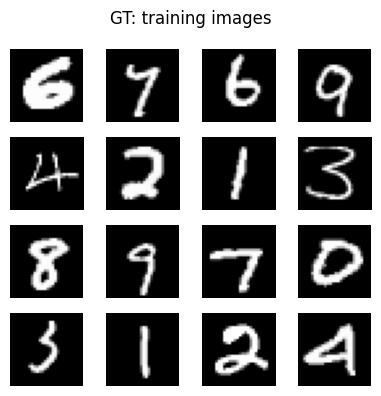

In [ ]:
# MNIST pixel 범위 [0,1]을 [-1,1]로 변환한다. label은 이 실험에서 사용하지 않는다.
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((.5,), (.5,))])
full_train = datasets.MNIST('/content/data', train=True, download=True, transform=transform)
# 고정 seed로 train/validation을 분리하고, 공식 test는 최종 평가에만 사용한다.
train, val = random_split(full_train, [55000,5000], generator=torch.Generator().manual_seed(SEED))
test = datasets.MNIST('/content/data', train=False, download=True, transform=transform)
loader_rng = torch.Generator().manual_seed(SEED)
loader = DataLoader(train, batch_size=BATCH, shuffle=True, generator=loader_rng, num_workers=0)
val_loader = DataLoader(val, batch_size=BATCH, shuffle=False, num_workers=0)
test_loader = DataLoader(test, batch_size=BATCH, shuffle=False, num_workers=0)
print('train / val / test:', len(train), len(val), len(test))

def show(x, title='', rows=4):
    x = x.detach().cpu().reshape(-1,28,28)
    cols = math.ceil(len(x)/rows)
    fig, axes = plt.subplots(rows,cols,figsize=(cols,rows),squeeze=False)
    # clipping은 시각화에만 적용한다. 실제 생성 tensor는 바꾸지 않는다.
    for ax, im in zip(axes.flat,x): ax.imshow(im.clamp(-1,1),cmap='gray',vmin=-1,vmax=1)
    for ax in axes.flat: ax.axis('off')
    fig.suptitle(title); plt.tight_layout(); plt.show()

preview = torch.stack([train[i][0] for i in range(16)]).flatten(1)
show(preview, 'GT: training images')


## 2. 일반식에서 현재 실험까지: probability path

교재 **Holderrieth·Erives, An Introduction to Flow Matching and Diffusion Models**, §3.1–3.3, §4.1–4.3을 따라 **일반식 → Gaussian conditional probability path → linear coefficients → 코드** 순서로 전개한다. 교재의 velocity field $u_t$를 이 노트북에서는 $v_t$로 쓴다. $d=784$이며 수식의 squared norm은 코드에서 pixel 평균을 내기 위해 $d$로 나눈다.

### 2.1 일반적인 conditional probability path와 marginal probability path

먼저 데이터 하나 $z$를 고정한다. 원하는 conditional probability path는

$$p_0(\cdot\mid z)=p_{\mathrm{init}},\qquad p_1(\cdot\mid z)=\delta_z.$$

즉, 처음에는 noise이고 마지막에는 그 이미지 하나로 모인다. $\delta_z$는 항상 $z$만 나오는 분포다. 이제 $z$도 data distribution에서 뽑으면 여러 이미지로 가는 **marginal probability path**가 된다.

$$p_t(x)=\int p_t(x\mid z)p_{\mathrm{data}}(z)\,dz.$$

$$z\sim p_{\mathrm{data}},\quad x_t\sim p_t(\cdot\mid z)
\quad\Longrightarrow\quad x_t\sim p_t.$$

이로부터 $p_0=p_{\mathrm{init}}$, $p_1=p_{\mathrm{data}}$다. 실제로는 dataset에서 $z$를 뽑으면 되므로, 복잡한 density $p_{\mathrm{data}}(z)$를 직접 계산할 필요가 없다. 유한 dataset을 분포로 사용하면 위 적분은 데이터에 대한 평균으로 해석할 수 있다.

여기서 **conditional은 숫자 label을 주는 conditional generation과 다르다.** 학습 정답을 만들기 위해 깨끗한 이미지 $z$를 고정한다는 뜻이다. 이 실험의 network 입력은 $(x_t,t)$이고 $z$나 숫자 label은 입력하지 않는다.

### 2.2 Gaussian을 선택하면 어떻게 되는가?

위 일반식에는 아직 Gaussian 가정이 없다. 이제 계산과 sampling이 쉬운 경로를 **선택**한다.

$$p_t(x\mid z)=\mathcal N(x;\alpha_t z,\beta_t^2 I),\qquad
x_t=\alpha_t z+\beta_t\epsilon,\quad\epsilon\sim\mathcal N(0,I).$$

$z$와 $\epsilon$은 독립이다. boundary conditions는 $\alpha_0=0,\beta_0=1,\alpha_1=1,\beta_1=0$이다. $\beta_1=0$은 density가 아닌 $\delta_z$로 가는 극한으로 이해한다.

**Gaussian인 것은 이미지 한 장을 고정했을 때의 $p_t(x\mid z)$다.** MNIST data distribution이나 여러 이미지를 섞은 $p_t(x)$ 전체가 하나의 Gaussian이라는 뜻이 아니다. 각 이미지 주위의 Gaussian을 섞으면 복잡한 분포가 된다.

현재 실험은 그중에서도 $\alpha_t=t$, $\beta_t=1-t$를 선택한다.

$$\boxed{x_t=tz+(1-t)\epsilon},\qquad t=0:\text{ noise},\quad t=1:\text{ data}.$$

이 linear coefficients는 Gaussian 가정만으로 자동 결정되지 않는다. 우리가 추가로 정한 설계다. 아래 interpolation 이미지는 같은 $z,\epsilon$을 고정한 채 $t$만 바꾼 결과다.

*교재 연결: 식 (11)–(16), Example 8, pp.14–16.*

### 2.3 Flow Matching: 왜 conditional velocity를 정답으로 쓸 수 있을까?

원하는 probability path를 따르는 velocity는 **continuity equation**을 만족해야 한다.

$$\partial_t p_t(x)+\nabla_x\cdot\bigl(p_t(x)v_t(x)\bigr)=0.$$

각 $z$에 대해 이 식을 만족하는 conditional velocity $v_t(x\mid z)$를 찾았다고 하자. conditional continuity equation을 $p_{\mathrm{data}}(z)$로 평균내면

$$\partial_t p_t(x)
=-\nabla_x\cdot\int p_t(x\mid z)v_t(x\mid z)p_{\mathrm{data}}(z)\,dz.$$

따라서 다음 velocity를 사용하면 marginal probability path의 continuity equation도 만족한다.

$$\boxed{v_t(x)=\int v_t(x\mid z)\frac{p_t(x\mid z)p_{\mathrm{data}}(z)}{p_t(x)}\,dz
=\mathbb E[v_t(x_t\mid z)\mid x_t=x].}$$

이 값은 **각 원본 $z$에 대한 conditional velocity를 posterior $p_t(z\mid x)$로 가중 평균한 값**이다. 같은 noisy 이미지에 여러 원본이 대응할 수 있으므로 원본별 target velocity도 다를 수 있다.

원래 목표는 계산하기 어려운 marginal velocity에 맞추는 것이다.

$$\mathcal L_{\mathrm{FM}}=\mathbb E\!\left[\frac1d\lVert v_\theta(x_t,t)-v_t(x_t)\rVert_2^2\right].$$

대신 sample별로 계산 가능한 conditional velocity를 정답으로 사용한다.

$$\mathcal L_{\mathrm{CFM}}=\mathbb E\!\left[\frac1d\lVert v_\theta(x_t,t)-v_t(x_t\mid z)\rVert_2^2\right].$$

왜 가능한가? $Y=v_t(x_t\mid z)$, $m=\mathbb E[Y\mid x_t,t]=v_t(x_t)$라 두고 오차를 분해하면

$$\mathbb E\lVert v_\theta-Y\rVert_2^2
=\mathbb E\lVert v_\theta-m\rVert_2^2+\mathbb E\lVert Y-m\rVert_2^2.$$

cross term은 $\mathbb E[Y-m\mid x_t,t]=0$이므로 사라진다. 마지막 항은 $\theta$와 무관하다. 따라서 두 loss의 gradient가 같고, 충분한 model capacity와 optimization이 가능하다면 conditional target에 대한 regression으로 marginal velocity를 배운다. **conditional target에 대한 MSE는 이상적인 모델에서도 0이 아닐 수 있다.**

*교재 연결: Theorem 9, 식 (18); continuity equation과 Theorem 12, 식 (24)–(26), pp.16–21.*

### 2.4 Gaussian을 대입해보자

conditional probability path를 만드는 한 가지 방법은 같은 $z,\epsilon$을 고정한 채

$$x_t=\alpha_t z+\beta_t\epsilon$$

을 움직이는 것이다. 시간으로 미분하면

$$\frac{dx_t}{dt}=\dot\alpha_t z+\dot\beta_t\epsilon.$$

$\beta_t>0$에서 $\epsilon=(x-\alpha_t z)/\beta_t$를 대입하여, 위치 $x$에서의 conditional velocity로 쓰면

$$\boxed{v_t(x\mid z)=\left(\dot\alpha_t-\frac{\dot\beta_t}{\beta_t}\alpha_t\right)z
+\frac{\dot\beta_t}{\beta_t}x.}$$

이 velocity에 따라 sample을 움직이면, 각 시점의 distribution이 우리가 정한 Gaussian probability path를 따른다. sampling한 $x_t=\alpha_tz+\beta_t\epsilon$을 $x$에 대입하면

$$v_t(x_t\mid z)=\dot\alpha_t z+\dot\beta_t\epsilon$$

이므로 일반 CFM loss에 대입하면

$$\mathcal L_{\mathrm{CFM}}
=\mathbb E\!\left[\frac1d\left\lVert v_\theta(\alpha_t z+\beta_t\epsilon,t)
-(\dot\alpha_t z+\dot\beta_t\epsilon)\right\rVert_2^2\right].$$

이전에 설정한 **linear coefficients** $\alpha_t=t,\beta_t=1-t$를 넣으면 $\dot\alpha_t=1,\dot\beta_t=-1$이므로

$$\boxed{v_t(x_t\mid z)=z-\epsilon},\qquad
\boxed{\mathcal L_{\mathrm{flow}}=\mathbb E\!\left[\frac1d\lVert v_\theta(x_t,t)-(z-\epsilon)\rVert_2^2\right].}$$

아래는 뒤의 학습 코드와 대응되는 부분이다.
```python
xt = t*z + (1-t)*eps
pred = models['flow'](xt, t)     # MLP 출력 자체가 velocity 예측
loss = (pred - (z-eps)).square().mean()
```

$z-\epsilon$이 $t$와 무관해도 **학습된 marginal velocity**는 $(x_t,t)$에 따라 달라진다. 시간별로 가능한 원본들의 posterior distribution이 달라지기 때문이다. network는 학습에 사용한 각 쌍의 직선 경로를 그대로 외워 재생하는 것이 아니다.

*교재 연결: Example 13, 식 (28)–(31), Algorithm 3, p.22.*

### 2.5 Score Matching → Gaussian 대입 → Noise Prediction

Score는 현재 위치에서 log-density가 가장 빠르게 증가하는 방향이다.

$$s_t(x)=\nabla_x\log p_t(x),\qquad s_t(x\mid z)=\nabla_x\log p_t(x\mid z).$$

marginal density의 정의 $p_t(x)=\int p_t(x\mid z)p_{\mathrm{data}}(z)\,dz$를 대입하고, gradient를 적분 안으로 옮기면

$$\begin{aligned}
s_t(x)
&=\frac{\nabla_x p_t(x)}{p_t(x)}\\
&=\frac{1}{p_t(x)}\nabla_x\int p_t(x\mid z)p_{\mathrm{data}}(z)\,dz\\
&=\frac{1}{p_t(x)}\int \nabla_x p_t(x\mid z)\,p_{\mathrm{data}}(z)\,dz.
\end{aligned}$$

이제 conditional score의 정의를 정리하면

$$s_t(x\mid z)=\frac{\nabla_x p_t(x\mid z)}{p_t(x\mid z)}
\quad\Longrightarrow\quad
\nabla_x p_t(x\mid z)=s_t(x\mid z)p_t(x\mid z).$$

이 식을 위 적분에 넣으면

$$\begin{aligned}
s_t(x)
&=\frac{1}{p_t(x)}\int s_t(x\mid z)p_t(x\mid z)p_{\mathrm{data}}(z)\,dz\\
&=\int s_t(x\mid z)\underbrace{\frac{p_t(x\mid z)p_{\mathrm{data}}(z)}{p_t(x)}}_{p_t(z\mid x)}\,dz\\
&=\mathbb E[s_t(x_t\mid z)\mid x_t=x].
\end{aligned}$$

마지막 두 줄에서는 Bayes' rule을 사용했다. $p_t(z\mid x)$는 현재 $x_t=x$를 관측했을 때 원본 $z$에 대한 posterior다. 즉, **marginal score는 현재 위치 $x$를 만들었을 법한 원본들의 conditional score를 posterior로 가중 평균한 값**이다.

따라서 Flow Matching에서와 마찬가지로, marginal score 대신 conditional score를 target으로 사용해 학습할 수 있다.

$$\mathcal L_{\mathrm{CSM}}=
\mathbb E\!\left[\frac1d\lVert s_\theta(x_t,t)-s_t(x_t\mid z)\rVert_2^2\right].$$

이는 marginal score에 대한 MSE와 $\theta$에 무관한 항만 다르다. 이 loss 비교는 expectation이 유한한 조건에서 성립한다. 경계에서 발산하는 경우에는 시간 구간을 제한하거나 적절한 weight를 사용해야 한다.

**Gaussian을 대입.** $p_t(x\mid z)=\mathcal N(x;\alpha_t z,\beta_t^2I)$의 log-density는

$$\log p_t(x\mid z)=C(t)-\frac{\lVert x-\alpha_t z\rVert_2^2}{2\beta_t^2}.$$

$x$로 미분하고 $x_t=\alpha_tz+\beta_t\epsilon$을 넣으면

$$\boxed{s_t(x\mid z)=-\frac{x-\alpha_tz}{\beta_t^2}},\qquad
\boxed{s_t(x_t\mid z)=-\frac{\epsilon}{\beta_t}}.$$

따라서

$$\mathcal L_{\mathrm{CSM}}
=\mathbb E\!\left[\frac1d\left\lVert s_\theta(x_t,t)+\frac{\epsilon}{\beta_t}\right\rVert_2^2\right].$$

**Noise 출력으로 바꾸기.** $\epsilon_\theta=-\beta_t s_\theta$로 표현하면

$$\mathcal L_{\mathrm{CSM}}
=\mathbb E\!\left[\frac{1}{d\beta_t^2}\lVert\epsilon_\theta(x_t,t)-\epsilon\rVert_2^2\right].$$

이 단계까지는 단순한 표현 변경이다. 그런데 $\beta_t\to0$에서 $1/\beta_t^2$가 커진다. 교재 Example 23과 같이 그 weight를 제거하면 지금 사용하는 **다른 weighting의 objective**가 된다.

$$\boxed{\mathcal L_{\mathrm{noise}}
=\mathbb E\!\left[\frac1d\lVert\epsilon_\theta(x_t,t)-\epsilon\rVert_2^2\right]
=\mathbb E\!\left[\frac{\beta_t^2}{d}\lVert s_\theta-s_t(x_t\mid z)\rVert_2^2\right].}$$

즉, plain noise MSE는 **weighted conditional score matching**이다. 전체 loss에 상수 하나를 곱한 것과는 다르다. 시간별 상대적 중요도가 달라져 유한한 MLP의 학습 결과도 달라질 수 있다. 충분히 표현할 수 있는 이상적인 regression의 시간별 최적 예측은 $\epsilon^*(x,t)=\mathbb E[\epsilon\mid x_t=x,t]$다.

**현재 linear coefficients 대입:** $\beta_t=1-t$이므로 학습 target은 $\epsilon$이고, 배운 모델에서 score를 꺼낼 때는

$$\boxed{s_\theta(x,t)=-\frac{\epsilon_\theta(x,t)}{1-t}}\quad (t<1).$$

```python
xt = t*z + (1-t)*eps
pred = models['noise'](xt, t)    # MLP 출력 자체가 noise 예측
loss = (pred - eps).square().mean()
# score가 필요할 때: s = -pred / (1-t)
```

Flow 모델과 Noise 모델은 같은 입력을 받아 같은 shape의 vector를 출력한다. Flow 모델은 velocity를, Noise 모델은 noise를 예측하도록 서로 다른 target으로 학습한다. Noise 모델의 loss는 score로 변환하지 않고 예측한 noise와 실제 noise를 직접 비교해 계산한다.

*교재 연결: 식 (38)–(40), Theorem 22, Example 23, Algorithm 4, pp.25, 31–32.*

### 2.6 Noise prediction으로 어떻게 이미지를 생성할까?

앞에서 두 모델을 학습하는 방법을 정했다. Flow 모델은 velocity를, Noise 모델은 noise를 예측한다. 그런데 ODE로 이미지를 생성하려면 **현재 위치에서 어느 방향으로 얼마나 움직일지**, 즉 velocity가 필요하다. 따라서 Noise 모델의 출력은 velocity로 변환해야 한다.

**① 먼저 현재 선형 path에서 관계를 확인하자.**

학습할 때 우리가 만든 sample과 그 conditional velocity target은

$$x_t=tz+(1-t)\epsilon,\qquad v_t(x_t\mid z)=z-\epsilon.$$

첫 식에서 $\epsilon$을 빼면

$$x_t-\epsilon=tz+(1-t)\epsilon-\epsilon=t(z-\epsilon).$$

따라서 $t>0$에서

$$\boxed{z-\epsilon=\frac{x_t-\epsilon}{t}.}$$

즉, 현재 sample $x_t$와 그것을 만들 때 사용한 noise $\epsilon$을 알면, 원본 $z$를 식에 직접 넣지 않고도 conditional velocity를 계산할 수 있다.

**② 생성할 때는 실제 noise 대신 모델의 예측을 사용한다.**

생성 중의 위치 $x$에는 학습 sample처럼 알려진 원본 $z$와 noise $\epsilon$ 쌍이 없다. 또한 같은 $(x,t)$를 만들 수 있는 쌍이 여러 개일 수 있으므로, Noise 모델이 항상 특정 쌍의 noise를 정확히 찾아내는 것도 아니다.

MSE로 학습하는 이상적인 Noise 모델은 그 가능한 noise들의 conditional mean을 예측한다.

$$\epsilon^*(x,t):=\mathbb E[\epsilon\mid x_t=x].$$

여기서 $\epsilon^*$는 이상적인 예측값이고, $\epsilon_\theta$는 실제 MLP의 예측값이다. 위 ①의 식을 $x_t=x$라는 조건 아래 평균내면

$$\begin{aligned}
v_t(x)
&=\mathbb E[z-\epsilon\mid x_t=x]\\
&=\mathbb E\left[\frac{x_t-\epsilon}{t}\,\middle|\,x_t=x\right]\\
&=\frac{x-\mathbb E[\epsilon\mid x_t=x]}{t}
=\frac{x-\epsilon^*(x,t)}{t}.
\end{aligned}$$

따라서 실제 모델에서는 다음처럼 velocity를 추정한다.

$$\boxed{\widehat v_{\mathrm{noise}}(x,t)=\frac{x-\epsilon_\theta(x,t)}{t}.}$$

이것이 뒤의 `generate()`에서 사용하는 변환이다.

```python
pred = net(x, t)
# Flow 모델: 출력 자체가 velocity
# Noise 모델: 예측한 noise를 velocity로 변환
v = pred if kind == 'flow' else (x - pred) / t
```

이렇게 구한 velocity를 ODE solver에 넣으면 두 모델 모두 이미지를 생성할 수 있다. Noise 모델이라고 반드시 SDE로만 생성해야 하는 것은 아니다.

**③ 일반적인 Gaussian path에서도 같은 방식으로 유도할 수 있다.**

계수가 $t$, $1-t$가 아니라 일반적인 $\alpha_t$, $\beta_t$여도 출발점은 같다.

$$x_t=\alpha_t z+\beta_t\epsilon,\qquad
v_t(x_t\mid z)=\dot\alpha_t z+\dot\beta_t\epsilon.$$

$\alpha_t\ne0$에서 첫 식을 $z=(x_t-\beta_t\epsilon)/\alpha_t$로 정리해 두 번째 식에 넣으면

$$\begin{aligned}
v_t(x_t\mid z)
&=\dot\alpha_t\frac{x_t-\beta_t\epsilon}{\alpha_t}+\dot\beta_t\epsilon\\
&=\frac{\dot\alpha_t}{\alpha_t}x_t
+\left(\dot\beta_t-\frac{\dot\alpha_t\beta_t}{\alpha_t}\right)\epsilon.
\end{aligned}$$

②처럼 $x_t=x$라는 조건 아래 평균내면

$$v_t(x)=\frac{\dot\alpha_t}{\alpha_t}x
+\left(\dot\beta_t-\frac{\dot\alpha_t\beta_t}{\alpha_t}\right)\epsilon^*(x,t).$$

여기에 $\alpha_t=t$, $\beta_t=1-t$, $\dot\alpha_t=1$, $\dot\beta_t=-1$을 넣으면 앞에서 구한 $(x-\epsilon^*)/t$가 나온다. 또 앞 절의 관계 $\epsilon^*=-\beta_t s_t$를 넣으면 교재의 velocity–score 변환식이 된다.

$$v_t(x)=\frac{\dot\alpha_t}{\alpha_t}x
+\left(\frac{\dot\alpha_t\beta_t^2}{\alpha_t}-\dot\beta_t\beta_t\right)s_t(x).$$

**④ 둘 다 velocity로 바꿀 수 있다면, 학습 결과도 같을까?**

이상적인 예측값 사이에는 위 관계가 있지만, 실제 MLP는 오차가 있고 두 모델이 최소화하는 loss도 다르다. 현재 선형 path에서 Noise 모델의 변환 오차를 계산하면

$$\begin{aligned}
\widehat v_{\mathrm{noise}}(x_t,t)-(z-\epsilon)
&=\frac{x_t-\epsilon_\theta(x_t,t)}{t}-\frac{x_t-\epsilon}{t}\\
&=\frac{\epsilon-\epsilon_\theta(x_t,t)}{t}.
\end{aligned}$$

예를 들어 $t=0.1$이면 noise 예측 오차가 velocity로 변환될 때 10배가 된다. 제곱 오차는 100배다. 따라서 noise MSE가 작아 보여도 작은 $t$에서의 velocity 오차는 클 수 있다.

위 식을 제곱해 정리하면 loss의 관계도 보인다.

$$\boxed{\lVert\epsilon_\theta-\epsilon\rVert_2^2
=t^2\lVert\widehat v_{\mathrm{noise}}-(z-\epsilon)\rVert_2^2.}$$

Flow 모델은 velocity MSE를 직접 최소화한다. Noise 모델은 변환된 velocity의 MSE에 $t^2$를 곱한 값을 최소화하는 셈이다. 그래서 두 모델의 자체 loss 숫자만 비교하지 않고, 뒤에서 **같은 velocity target에 대한 오차를 시간 구간별로 확인**한다.

*교재 연결: Proposition 1, 식 (41)–(42), p.26. ①·②·④는 현재 선형 path에 대한 유도다.*


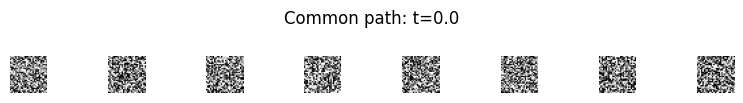

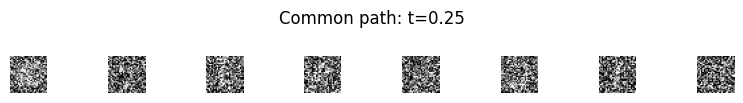

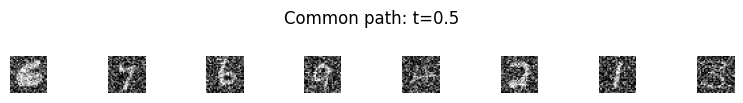

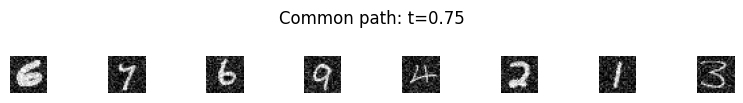

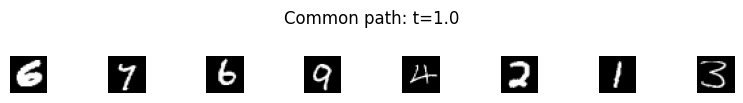

In [ ]:
rng = torch.Generator().manual_seed(100)
eps_preview = torch.randn(preview.shape, generator=rng)
for tv in [0., .25, .5, .75, 1.]:
    show(tv*preview[:8]+(1-tv)*eps_preview[:8], f'Common path: t={tv}', rows=1)


## 3. 공통 MLP — 출력에 보정항을 붙이지 않는다
시간 하나를 sin/cos 64차원으로 표현하고 1024차원으로 투영한다. 이미지도 1024차원으로 투영하며, 각 residual block에 시간 정보를 더한다. 마지막 Linear 출력 자체가 학습 target의 예측값이다.

MLP **내부**의 residual connection은 두 모델에 동일하다. MLP 출력에 $-x+f$ 또는 $x+tf$ 같은 별도의 보정식은 적용하지 않는다. 마지막 층을 0으로 초기화해 두 모델 모두 0 예측에서 출발한다. 동일한 weights가 각 target에 똑같이 유리하다는 의미는 아니다.


In [ ]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim=64):
        super().__init__()
        # 32개 frequency의 sin/cos로 64차원 embedding을 만든다. 64개의 time step이 아니다.
        self.register_buffer('freq', 2*math.pi*torch.logspace(0,2,dim//2))
    def forward(self,t):
        # t: [B,1], freq[None,:]: [1,32] → broadcasting 결과: [B,32]
        a = t*self.freq[None,:]
        return torch.cat([a.sin(),a.cos()],dim=1)

class MLP(nn.Module):
    def __init__(self, width=1024, depth=3):
        super().__init__()
        self.time = nn.Sequential(TimeEmbedding(64),nn.Linear(64,width),nn.SiLU())
        self.input = nn.Linear(784,width)
        self.blocks = nn.ModuleList([
            nn.Sequential(nn.LayerNorm(width),nn.SiLU(),nn.Linear(width,width),
                          nn.SiLU(),nn.Linear(width,width)) for _ in range(depth)])
        self.output = nn.Linear(width,784)
        nn.init.zeros_(self.output.weight); nn.init.zeros_(self.output.bias)
    def forward(self,x,t):
        te, h = self.time(t), self.input(x)
        for block in self.blocks:
            h = h + block(h+te)/math.sqrt(len(self.blocks))
        # x: [B,784], t: [B,1] → [B,784]. 학습 target에 따라 velocity 또는 noise로 해석한다.
        return self.output(h)


## 4. 공통 평가·생성 함수
validation에서는 같은 이미지에 같은 t와 noise를 사용한다. 전체 noise/velocity MSE와 함께, 양쪽 모델을 velocity로 해석한 **시간 구간별 오차**를 측정한다. 경계의 수치 민감도를 구분하기 위해 구간별 평가는 각 구간 내부에서 t를 뽑는다.

ODE는 두 모델 모두 동일 Heun 적분을 쓴다. noise→velocity 변환은 t=0에서 정의되지 않으므로 두 모델 모두 $\delta\to1-\delta$에서 비교한다. $N(0,I)$ 시작은 $p_\delta$의 근사이며 끝도 data distribution의 근사다. 기본 δ=0.01을 고정하고 민감도 실험은 따로 한다. 적분 중 clipping과 마지막 denoise는 사용하지 않는다.

Noise 모델의 SDE는 같은 경로에 대한
$$dX_t=[v_\theta+\tfrac12g(t)^2s_\theta]dt+g(t)dW_t,\qquad g(t)^2=2\kappa(1-t)$$
이므로 drift는 $v_\theta-\kappa\epsilon_\theta$다. κ=0은 ODE다. 정확한 장과 continuous time에서 같은 marginal probability path를 따르지만 근사 모델/numerical integration에서는 차이가 난다.


### 4.1 ODE에서 SDE로: 일반식 → 현재 sampler

**일반식.** 정확한 marginal velocity $v_t$를 알면 $dX_t=v_t(X_t)dt$가 원하는 경로 $p_t$를 따른다. 여기에 무작정 noise만 추가하면 경로가 달라진다. 시간에만 의존하는 diffusion coefficient $g(t)$에 대해 다음처럼 score 보정을 함께 더한다.

$$\boxed{dX_t=\left[v_t(X_t)+\frac{g(t)^2}{2}s_t(X_t)\right]dt+g(t)dW_t.}$$

이유는 SDE의 Fokker–Planck equation에서 볼 수 있다. Drift를 $b_t$라고 하면

$$\partial_t p_t=-\nabla\cdot(p_tb_t)+\frac{g(t)^2}{2}\Delta p_t.$$

$b_t=v_t+\frac12g(t)^2s_t$, $p_ts_t=\nabla p_t$를 넣으면

$$\partial_t p_t=-\nabla\cdot(p_tv_t)
-\frac{g(t)^2}{2}\Delta p_t+\frac{g(t)^2}{2}\Delta p_t
=-\nabla\cdot(p_tv_t).$$

noise가 분포를 퍼뜨리는 항과 score 보정항이 상쇄되어 원래 ODE와 같은 marginal probability path가 남는다. 이는 필요한 regularity conditions 아래 정확한 장을 사용하는 continuous time의 결과다. sample 하나의 trajectory까지 같다는 뜻은 아니다.

**Gaussian + linear coefficients를 대입.** 앞에서 얻은

$$\widehat v_{\mathrm{noise}}=\frac{x-\epsilon_\theta}{t},\qquad
s_\theta=-\frac{\epsilon_\theta}{1-t}$$

를 사용한다. 여기에 이 실험에서 **추가로 선택한** $g(t)^2=2\kappa(1-t)$를 대입하면

$$b_\theta=\widehat v_{\mathrm{noise}}
+\frac{2\kappa(1-t)}{2}\left(-\frac{\epsilon_\theta}{1-t}\right)
=\boxed{\widehat v_{\mathrm{noise}}-\kappa\epsilon_\theta}.$$

이것이 아래 `generate()`의 `v-kappa*ep`다. Euler–Maruyama 한 step은

$$x_{t+\Delta t}\approx x_t+\Delta t\,(\widehat v_{\mathrm{noise}}-\kappa\epsilon_\theta)
+\sqrt{2\kappa(1-t)\Delta t}\,\xi,\qquad \xi\sim\mathcal N(0,I).$$

여기서 $\xi$는 매 생성 step마다 새로 뽑는 난수로, 학습 때 입력을 만들던 $\epsilon$과 역할이 다르다.

```python
ep = net(x, t)
v = (x-ep)/t
x = x + dt*(v-kappa*ep) + math.sqrt(2*kappa*(1-ti)*dt)*noise
```

$\kappa=0$이면 이론상 ODE가 된다. 실제 코드에서는 한 time step마다 velocity를 두 번 계산하고, 두 값의 평균으로 위치를 업데이트하는 Heun method를 사용한다. $v_1=v_\theta(x,t)$, $x'=x+\Delta t\,v_1$, $v_2=v_\theta(x',t+\Delta t)$를 구해 $x\leftarrow x+\frac{\Delta t}{2}(v_1+v_2)$로 갱신한다.

변환식은 $t=0$ 또는 $t=1$에서 나눗셈 문제가 있으므로 코드는 $\delta\to1-\delta$를 적분한다. 시작 Gaussian은 정확한 $p_\delta$가 아니라 근사다. 근사 모델·끝점 절단·유한 step의 numerical error 때문에 ODE와 SDE의 실제 생성 품질은 달라질 수 있다.

*교재 연결: Theorem 17, 식 (44)–(45); Example 18, 식 (46); Theorem 19, 식 (49), pp.27–29. $g(t)$는 교재의 $\sigma_t$에 해당하며 Gaussian probability path의 standard deviation $\beta_t$와는 다른 양이다.*

In [ ]:
@torch.no_grad()
def evaluate_pair(models, data_loader, seed=2026):
    for net in models.values(): net.eval()
    # 매 평가마다 같은 t/noise를 재생성해 validation의 random fluctuation을 줄인다.
    rng = torch.Generator(device=device).manual_seed(seed)
    totals = {'flow':0., 'noise':0.}; count=0
    for z,_ in data_loader:
        z=z.to(device).flatten(1)
        t=torch.rand((len(z),1),device=device,generator=rng)
        eps=torch.randn(z.shape,device=device,generator=rng)
        xt=t*z+(1-t)*eps
        targets={'flow':z-eps,'noise':eps}
        for name,net in models.items():
            totals[name] += (net(xt,t)-targets[name]).square().mean().item()*len(z)
        count += len(z)
    return {k:v/count for k,v in totals.items()}

@torch.no_grad()
def velocity_errors(models, data_loader, seed=555, max_batches=8):
    for net in models.values(): net.eval()
    # 같은 conditional velocity target으로 비교한다. 작은 t의 변환 오차를 따로 확인한다.
    bins=[(.01,.05),(.05,.2),(.2,.5),(.5,.8),(.8,.95),(.95,.99)]
    rng=torch.Generator(device=device).manual_seed(seed)
    sums=np.zeros((len(bins),2)); count=0
    for batch,(z,_) in enumerate(data_loader):
        if batch >= max_batches: break
        z=z.to(device).flatten(1); count+=len(z)
        for i,(lo,hi) in enumerate(bins):
            t=lo+(hi-lo)*torch.rand((len(z),1),device=device,generator=rng)
            eps=torch.randn(z.shape,device=device,generator=rng)
            xt=t*z+(1-t)*eps; target=z-eps
            vf=models['flow'](xt,t)
            vn=(xt-models['noise'](xt,t))/t
            sums[i] += np.array([(vf-target).square().mean().item(),
                                 (vn-target).square().mean().item()])*len(z)
    return bins,sums/count

@torch.no_grad()
def generate(net, kind, x0, steps=200, delta=.01, kappa=0., seed=1234):
    # steps: numerical integration 횟수. delta: t=0,1의 singularity를 피하는 경계 여유.
    # kappa=0: Heun ODE (step당 2회 호출). kappa>0: noise 모델의 SDE (step당 1회 호출).
    # seed는 SDE의 추가 noise에 사용한다. 시작 noise x0는 호출자가 따로 지정한다.
    assert kind in ('flow','noise') and steps>0 and 0<delta<.5 and kappa>=0
    assert kappa==0 or kind=='noise', 'SDE 비교에서는 noise 모델을 고정합니다.'
    net.eval(); x=x0.clone()
    grid=torch.linspace(delta,1-delta,steps+1,device=x.device)
    rng=torch.Generator(device=x.device).manual_seed(seed)
    def velocity(x,t):
        pred=net(x,t)
        # 선형 Gaussian path에서 noise prediction을 velocity로 변환한다.
        return pred if kind=='flow' else (x-pred)/t
    for i in range(steps):
        ti,tj=grid[i].item(),grid[i+1].item(); dt=tj-ti
        t=torch.full((len(x),1),ti,device=x.device)
        if kappa==0:
            v=velocity(x,t)
            xp=x+dt*v
            tn=torch.full_like(t,tj)
            x=x+.5*dt*(v+velocity(xp,tn))
        else:
            ep=net(x,t); v=(x-ep)/t
            noise=torch.randn(x.shape,device=x.device,generator=rng)
            x=x+dt*(v-kappa*ep)+math.sqrt(2*kappa*(1-ti)*dt)*noise
    return x

def report_pixels(x):
    assert torch.isfinite(x).all(), 'NaN/Inf in generated samples'
    print('raw min/max:',x.min().item(),x.max().item(),
          'outside [-1,1]:',f'{100*((x<-1)|(x>1)).float().mean().item():.2f}%')


## 5. 통제된 학습 — 같은 batch로 두 모델을 각각 업데이트
각 batch에서 t/noise를 **한 번만 뽑아 공유**한다. 두 optimizer는 독립적이다. 각 모델의 gradient norm을 1로 clipping한다. 고정 cosine LR을 사용하며 validation에 따른 LR 변경·early stopping·각각의 best 모델 선택은 하지 않는다. 공통 epoch의 결과를 비교한다.




In [ ]:
CONFIG=dict(version='direct_pair_v1',seed=SEED,batch=BATCH,width=WIDTH,depth=DEPTH,
            lr=LR,min_lr=MIN_LR,schedule_epochs=SCHEDULE_EPOCHS,weight_decay=1e-4)
base=MLP(WIDTH,DEPTH).to(device)
# 구조뿐 아니라 initial weights까지 동일하게 시작한다. optimizer는 모델별로 독립적이다.
models={'flow':base,'noise':copy.deepcopy(base)}
assert all(torch.equal(a,b) for a,b in zip(models['flow'].state_dict().values(),models['noise'].state_dict().values()))
optimizers={k:torch.optim.AdamW(v.parameters(),lr=LR,weight_decay=1e-4) for k,v in models.items()}
train_rng=torch.Generator(device=device).manual_seed(SEED+1)
history=[]; start_epoch=0
# resume은 마지막으로 완료된 epoch 이후부터 시작한다. 중단된 epoch는 다시 실행한다.
# model/optimizer 및 RNG 상태를 함께 복원한다. 환경 변경 시 bitwise 재현은 보장하지 않는다.
if RESUME:
    ck=torch.load(CKPT,map_location='cpu',weights_only=False) # 직접 만든 체크포인트만
    assert ck['config']==CONFIG, '이전 실험 설정과 다릅니다. 새 RUN_DIR을 사용하세요.'
    for name in models:
        models[name].load_state_dict(ck['models'][name])
        optimizers[name].load_state_dict(ck['optimizers'][name])
    history=ck['history']; start_epoch=ck['epoch']
    train_rng.set_state(ck['train_rng']); loader_rng.set_state(ck['loader_rng'])
    torch.set_rng_state(ck['torch_rng'])
    if device.type=='cuda' and ck['cuda_rng'] is not None: torch.cuda.set_rng_state_all(ck['cuda_rng'])
    print('Resuming after epoch',start_epoch)
print('Parameters per model:',sum(p.numel() for p in base.parameters()))
fixed_noise=torch.randn((40,784),generator=torch.Generator().manual_seed(999)).to(device)

def atomic_save(obj,path):
    tmp=path.with_suffix('.tmp'); torch.save(obj,tmp); os.replace(tmp,path)

for epoch in range(start_epoch+1,MAX_EPOCHS+1):
    started=time.time()
    lr=MIN_LR+.5*(LR-MIN_LR)*(1+math.cos(math.pi*(epoch-1)/max(1,SCHEDULE_EPOCHS-1)))
    for name in models:
        models[name].train()
        for group in optimizers[name].param_groups: group['lr']=lr
    sums={k:0. for k in models}; count=0
    for z,_ in loader:
        z=z.to(device).flatten(1)
        # 같은 batch, t, noise를 두 모델에 공유한다. 학습 중 ODE/SDE 적분은 하지 않는다.
        t=torch.rand((len(z),1),device=device,generator=train_rng)
        eps=torch.randn(z.shape,device=device,generator=train_rng)
        xt=t*z+(1-t)*eps
        # Gaussian path의 conditional velocity target과 noise target.
        targets={'flow':z-eps,'noise':eps}
        for name,net in models.items():
            opt=optimizers[name]; opt.zero_grad(set_to_none=True)
            pred=net(xt,t)
            # batch와 784개 pixel 전체의 MSE. 두 모델의 자체 loss 크기는 직접 비교하지 않는다.
            loss=(pred-targets[name]).square().mean()
            if not torch.isfinite(loss): raise RuntimeError(f'{name}: non-finite loss')
            loss.backward(); nn.utils.clip_grad_norm_(net.parameters(),1.)
            opt.step(); sums[name]+=loss.item()*len(z)
        count+=len(z)
    val_losses=evaluate_pair(models,val_loader)
    row=dict(epoch=epoch,lr=lr,**{f'train_{k}':sums[k]/count for k in models},
             **{f'val_{k}':val_losses[k] for k in models})
    history.append(row)
    state=dict(config=CONFIG,epoch=epoch,history=history,
               models={k:v.state_dict() for k,v in models.items()},
               optimizers={k:v.state_dict() for k,v in optimizers.items()},
               train_rng=train_rng.get_state(),loader_rng=loader_rng.get_state(),
               torch_rng=torch.get_rng_state(),
               cuda_rng=torch.cuda.get_rng_state_all() if device.type=='cuda' else None)
    # last.pt: resume용 전체 상태. 매 epoch 갱신하며 best validation 모델을 선택하지 않는다.
    atomic_save(state,CKPT)
    # snapshot: 같은 epoch의 두 모델을 비교하기 위한 weights. optimizer/RNG는 포함하지 않는다.
    if epoch%50==0 or epoch==MAX_EPOCHS:
        atomic_save(dict(config=CONFIG,epoch=epoch,models=state['models']),RUN_DIR/f'epoch_{epoch:04d}.pt')
    (RUN_DIR/'history.json').write_text(json.dumps(history,indent=2))
    print(f'{epoch:03d}: flow train={row["train_flow"]:.5f}, val={row["val_flow"]:.5f} | '
          f'noise train={row["train_noise"]:.5f}, val={row["val_noise"]:.5f} | lr={lr:.2e}, seconds={time.time()-started:.0f}')
    if epoch%50==0:
        for name,net in models.items():
            samples=generate(net,name,fixed_noise)
            show(samples,f'Epoch {epoch}: {name}, same Heun ODE')
completed_epoch=history[-1]['epoch'] if history else 0
print('Common comparison epoch:',completed_epoch)


Output hidden; open in https://colab.research.google.com to view.

## 6. 학습 결과 비교 A — 같은 ODE로 생성
두 자체 loss 곡선은 별도 그래프에 그린다. 숫자 크기로 우열을 판단하지 않는다. 공통 velocity MSE는 같은 validation 입력에서 비교하며 작은 t의 오차를 따로 확인한다. 표시할 때만 pixel을 [-1,1]로 자르므로 raw 범위와 범위 이탈 비율도 같이 출력한다.


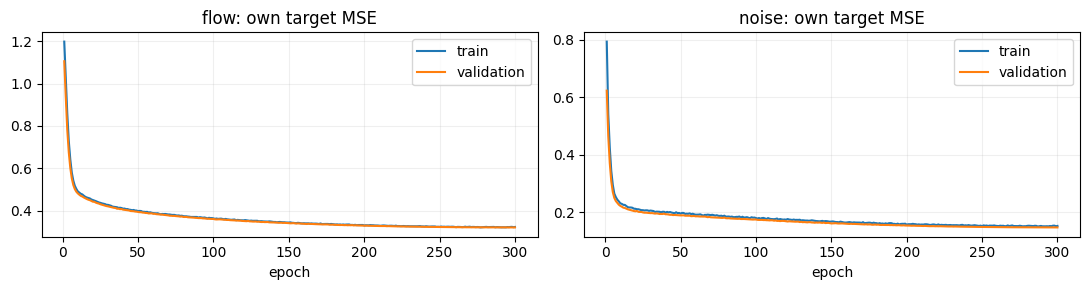

Validation: common velocity MSE (fixed subset, conditional targets)
(0.01, 0.05) {'flow': np.float64(0.3003501482307911), 'noise': np.float64(22.779391050338745)}
(0.05, 0.2) {'flow': np.float64(0.30426472797989845), 'noise': np.float64(0.6704259216785431)}
(0.2, 0.5) {'flow': np.float64(0.24597483687102795), 'noise': np.float64(0.3381486162543297)}
(0.5, 0.8) {'flow': np.float64(0.271102000027895), 'noise': np.float64(0.33720798045396805)}
(0.8, 0.95) {'flow': np.float64(0.4628991037607193), 'noise': np.float64(0.48576410859823227)}
(0.95, 0.99) {'flow': np.float64(0.7855073809623718), 'noise': np.float64(0.7200002446770668)}


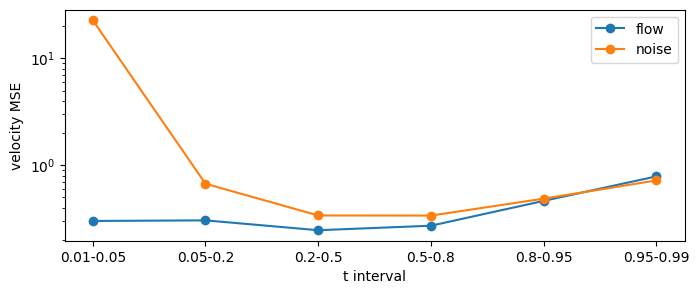

raw min/max: -2.341623306274414 3.2091426849365234 outside [-1,1]: 35.32%


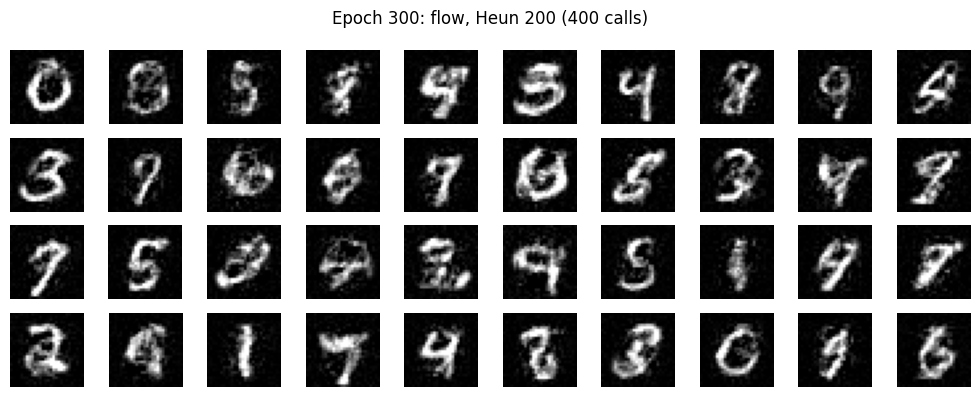

raw min/max: -4.928943634033203 4.755008220672607 outside [-1,1]: 42.67%


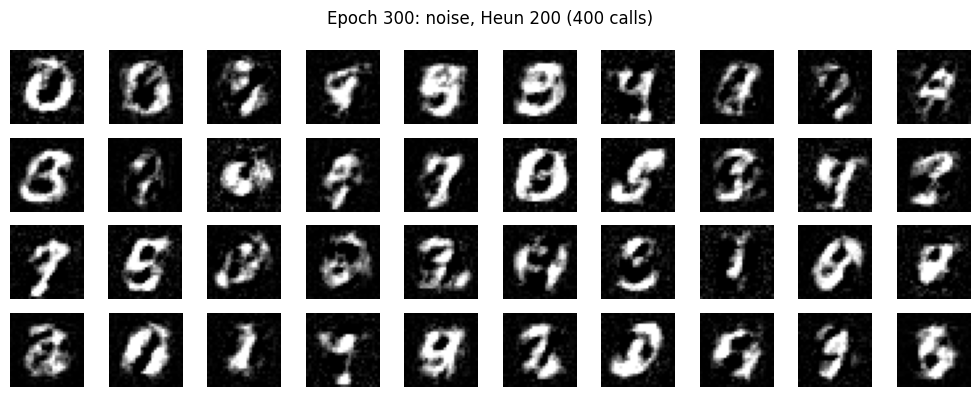

In [ ]:
fig,axes=plt.subplots(1,2,figsize=(11,3))
for ax,name in zip(axes,models):
    ax.plot([r['epoch'] for r in history],[r[f'train_{name}'] for r in history],label='train')
    ax.plot([r['epoch'] for r in history],[r[f'val_{name}'] for r in history],label='validation')
    ax.set_title(f'{name}: own target MSE'); ax.set_xlabel('epoch'); ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()
bins,errors=velocity_errors(models,val_loader)
print('Validation: common velocity MSE (fixed subset, conditional targets)')
for interval,values in zip(bins,errors): print(interval,dict(zip(models,values)))
fig,ax=plt.subplots(figsize=(8,3))
for j,name in enumerate(models): ax.plot(range(len(bins)),errors[:,j],marker='o',label=name)
ax.set_xticks(range(len(bins)),[f'{a}-{b}' for a,b in bins]); ax.set_yscale('log')
ax.set_xlabel('t interval'); ax.set_ylabel('velocity MSE'); ax.legend(); plt.show()
comparison={}
for name,net in models.items():
    comparison[name]=generate(net,name,fixed_noise,steps=200,delta=.01)
    report_pixels(comparison[name])
    show(comparison[name],f'Epoch {completed_epoch}: {name}, Heun 200 (400 calls)')


## 7. 공통 좌표에서 초기 분포·GT·생성 분포
PCA 축은 train 이미지로 한 번만 구한다. 같은 초기 noise를 두 모델에 넣고 같은 축에 투영한다. 이 그림은 784차원 분포의 일부만 보여주므로 품질 점수는 아니다. 점이 겹쳐도 획이 깨끗하다는 뜻은 아니다.


raw min/max: -2.7349846363067627 4.1032819747924805 outside [-1,1]: 35.74%
raw min/max: -5.770718097686768 8.705451965332031 outside [-1,1]: 42.09%


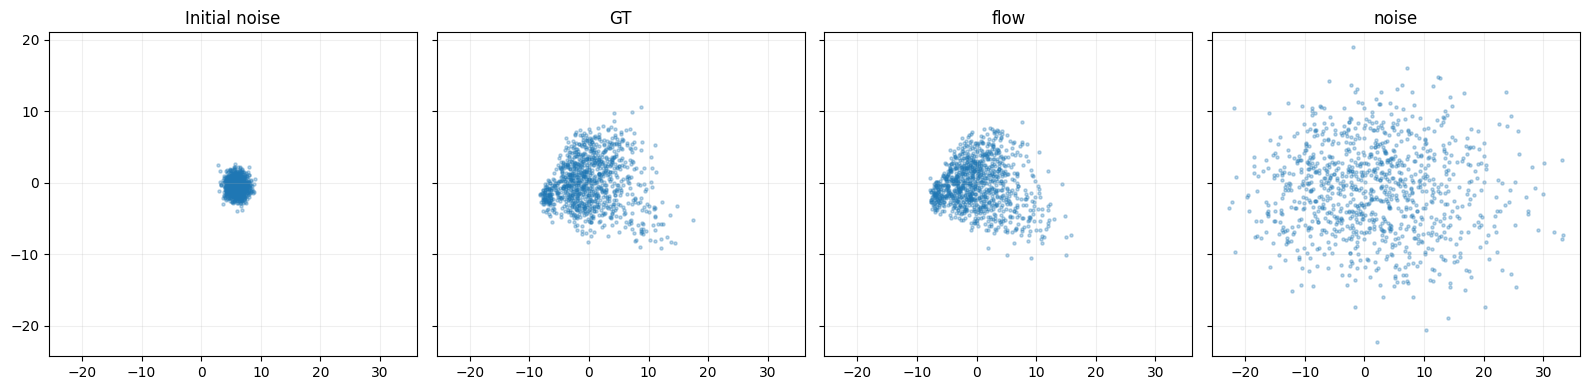

In [ ]:
# 시각화 비용을 조절할 sample 수. PCA 축은 train 이미지로만 한 번 계산한다.
N_COMPARE=1000
rng=torch.Generator().manual_seed(2026)
indices=torch.randperm(len(train),generator=rng)[:N_COMPARE]
gt=torch.stack([train[int(i)][0] for i in indices]).flatten(1)
prior=torch.randn((N_COMPARE,784),generator=rng)
center=gt.mean(0,keepdim=True)
with torch.random.fork_rng():
    torch.manual_seed(2026)
    _,_,vectors=torch.pca_lowrank(gt-center,q=2,center=False)
def project(x): return (x.detach().cpu()-center)@vectors[:,:2]
points={'Initial noise':project(prior),'GT':project(gt)}
for name,net in models.items():
    samples=torch.cat([generate(net,name,x.to(device)).cpu() for x in prior.split(128)])
    report_pixels(samples)
    points[name]=project(samples)
fig,axes=plt.subplots(1,4,figsize=(16,4),sharex=True,sharey=True)
for ax,(name,xy) in zip(axes,points.items()):
    ax.scatter(xy[:,0],xy[:,1],s=5,alpha=.3); ax.set_title(name); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()


## 8. sampler 비교 B — noise 모델 하나를 고정
앞의 학습 방법 비교와 구분한다. ODE Heun 200 step과 SDE Euler–Maruyama 400 step은 모델 호출 수가 각각 400회로 같다. 알고리즘/step은 다르므로 계산량을 맞춘 비교이며 순수한 κ 하나의 비교라고 부르지는 않는다. SDE seed를 3개 사용한다. 엄격한 통계적 우열 판정이 아니라 시각적 비교다.


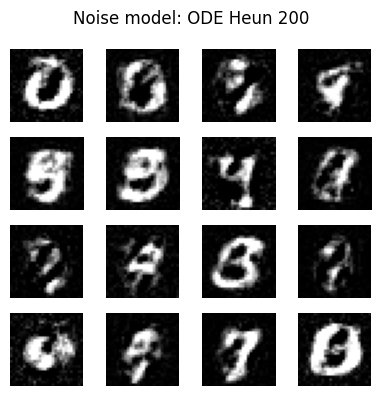

raw min/max: -3.90256929397583 4.891193866729736 outside [-1,1]: 41.41%


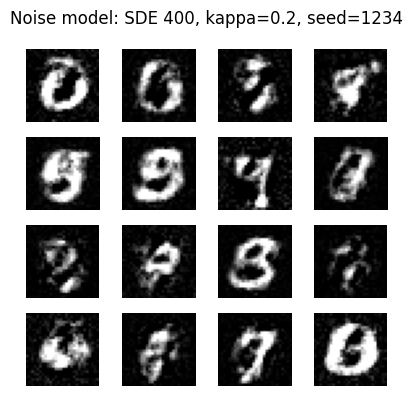

raw min/max: -4.239483833312988 4.21940279006958 outside [-1,1]: 42.37%


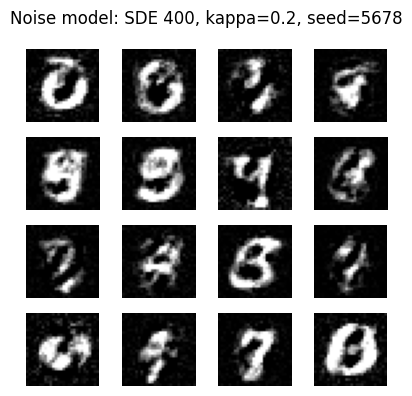

raw min/max: -4.081118583679199 4.376155853271484 outside [-1,1]: 40.66%


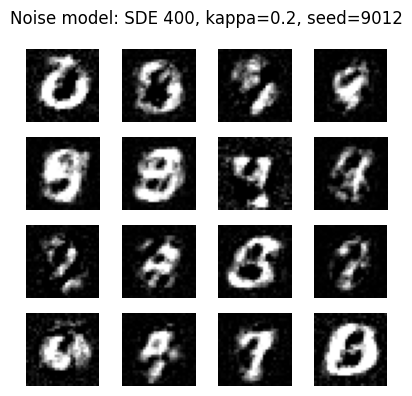

raw min/max: -3.607293128967285 4.5973334312438965 outside [-1,1]: 37.52%


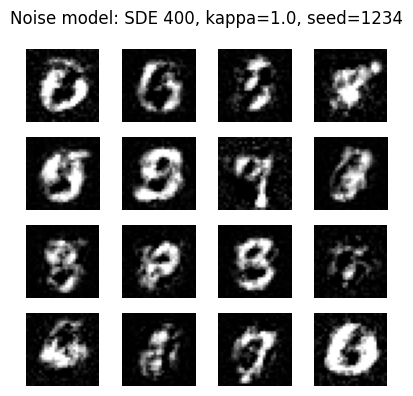

raw min/max: -3.989964246749878 3.845308303833008 outside [-1,1]: 39.48%


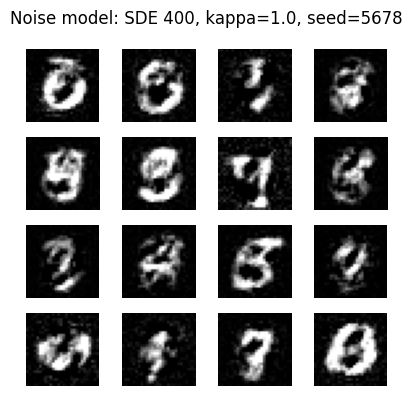

raw min/max: -3.724764823913574 4.332760810852051 outside [-1,1]: 38.43%


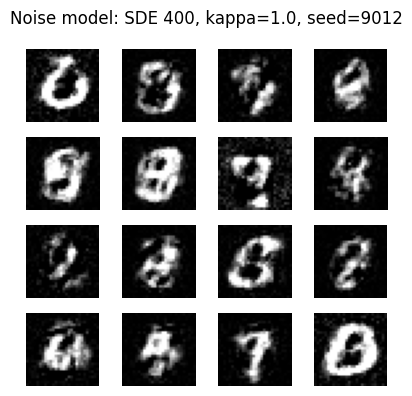

In [ ]:
# 같은 noise 모델과 x0를 사용한다. ODE 200 step과 SDE 400 step은 각 400회 모델 호출이다.
x0=fixed_noise[:16]
show(generate(models['noise'],'noise',x0,steps=200), 'Noise model: ODE Heun 200')
for kappa in [.2,1.]:
    for seed in [1234,5678,9012]:
        samples=generate(models['noise'],'noise',x0,steps=400,kappa=kappa,seed=seed)
        report_pixels(samples)
        show(samples,f'Noise model: SDE 400, kappa={kappa}, seed={seed}')


## 9. 최종 test — 실험 설정을 고정한 뒤 한 번 평가
test 자체 loss는 서로 다른 target이므로 직접 비교하지 않는다. 공통 시간 구간별 velocity MSE도 함께 기록한다. test 결과로 반복 튜닝하지 않는다.

추가 실험은 한 번에 하나씩 바꾼다: ODE steps 100/200/400, δ 0.005/0.01/0.02, 이후 새로운 학습 seed. 현재 한 쌍의 실행만으로 일반적인 우열을 결론 내리지 않는다. 두 objective의 차이와 출력 표현의 optimization 특성이 함께 포함된 비교다.


In [ ]:
print('Final test own-target MSE:',evaluate_pair(models,test_loader,seed=9876))
bins,test_errors=velocity_errors(models,test_loader,seed=9876,max_batches=len(test_loader))
for interval,values in zip(bins,test_errors): print(interval,dict(zip(models,values)))
print('Checkpoint:',CKPT,' / common epoch:',completed_epoch)


Final test own-target MSE: {'flow': 0.32482276220321654, 'noise': 0.15267234153747558}
(0.01, 0.05) {'flow': np.float64(0.30227331285476683), 'noise': np.float64(23.368908309936522)}
(0.05, 0.2) {'flow': np.float64(0.30418497867584227), 'noise': np.float64(0.6849977013587951)}
(0.2, 0.5) {'flow': np.float64(0.24066627507209779), 'noise': np.float64(0.33379687776565553)}
(0.5, 0.8) {'flow': np.float64(0.2663600500583649), 'noise': np.float64(0.3317367869853973)}
(0.8, 0.95) {'flow': np.float64(0.4595962490081787), 'noise': np.float64(0.4815344110012054)}
(0.95, 0.99) {'flow': np.float64(0.7760006381034851), 'noise': np.float64(0.7098770974159241)}
Checkpoint: /content/drive/MyDrive/MNIST_Controlled_Comparison/run_v1/last.pt  / common epoch: 300


## 10. 관찰한 결과와 한계

### 관찰한 결과

두 모델 모두 train·validation loss가 감소했지만, 생성 이미지의 품질은 기대한 만큼 좋지 않았다. 숫자를 알아볼 수 있는 sample도 있었지만, 일부 이미지에는 불분명한 형태와 거친 획이 남았다. 이번 실험을 통해 loss가 감소하는 것과 생성 이미지가 좋아지는 것을 구분해서 확인해야 한다는 점을 배웠다.

PCA projection에서는 Flow 모델의 sample이 Noise 모델보다 GT의 분포 형태를 더 비슷하게 따르는 것으로 보였다. 다만 이 그림은 784차원 데이터를 2차원에 투영한 결과이므로, 전체 distribution이 얼마나 일치하는지 또는 이미지 품질이 얼마나 좋은지를 단독으로 판단하는 기준으로 보지는 않는다.

### Loss 감소와 생성 품질의 차이

현재 loss는 생성 distribution과 GT distribution의 차이를 직접 측정하지 않는다. 실제 데이터로 만든 $(x_t,t)$에서 velocity 또는 noise target을 얼마나 잘 예측하는지를 측정한다. 생성할 때는 그 예측을 사용해 여러 time step을 진행하므로, 남아 있는 예측 오차와 numerical integration의 영향도 결과에 반영된다.

특히 Noise 모델은 예측을 velocity로 변환할 때 오차가 $1/t$배 커진다. 실제 시간 구간별 평가에서도 작은 $t$에서 Noise 모델의 velocity MSE가 크게 나타났다. 이는 noise MSE가 감소하더라도 생성 품질이 충분히 좋아지지 않을 수 있는 이유 중 하나로 생각할 수 있다. 다만 이 오차가 실제 이미지와 distribution 차이에 얼마나 영향을 주었는지는 이번 결과만으로 확정할 수 없다. Loss가 잘못 설계되었다고 단정하기보다, loss가 측정하는 대상과 최종 생성 품질이 다르다는 점으로 이해했다.

### 이번 실험의 한계

MLP의 표현 능력이나 이미지의 공간 구조를 직접 활용하지 않는 architecture가 생성 품질에 영향을 주었을 가능성이 있다. 하지만 architecture를 바꾸어 비교하지 않았으므로 현재 결과의 원인을 MLP로 확정할 수는 없다.

또한 이번 결과는 하나의 training seed와 제한된 설정에서 얻었다. ODE와 SDE의 비교도 모델 호출 수를 맞춘 시각적 비교이며, solver와 step 수가 함께 달라진다. 따라서 전체 Flow Matching과 diffusion 계열의 일반적인 우열을 결론 내릴 수 없다. 생성 이미지는 표시할 때 pixel 범위를 clipping하므로, 시각적 결과와 함께 출력한 raw 범위도 고려해야 한다.

### 배운 점과 다음 실험

이번 실습에서는 일반적인 probability path와 velocity·score의 관계에서 출발해, Gaussian path를 대입했을 때의 target과 loss를 유도하고 실제 학습·생성 코드로 연결했다. 동시에 train·validation loss만으로 생성 모델을 평가하기 어렵다는 점을 확인했다.

현재 실습을 baseline으로 두고, 이후에는 U-Net이나 DiT로 architecture를 변경하거나 conditional generation과 guidance를 추가해 결과가 얼마나 개선되는지 확인하고 싶다. Architecture의 효과를 비교할 때는 가능한 한 기존 학습 조건을 유지하고, guidance의 효과는 같은 conditional 모델에서 guidance strength를 바꾸어 살펴볼 예정이다.

우선 생성 품질은 **같은 initial noise에서 생성한 이미지의 숫자 식별 가능성, 획과 배경의 선명함, 다양성**을 시각적으로 비교해 평가할 예정이다. 일부 잘 나온 sample만 고르기보다 여러 sample을 함께 확인한다. Train·validation loss는 학습 상태를 확인하는 보조 지표로 사용하며, loss 감소 자체를 생성 품질의 개선으로 판단하지 않는다. 시각적 평가는 주관적이므로 정량적인 성능 우열을 입증하는 데에는 한계가 있다.
